# Student Tea & Snack Preferences
- **Student Name:** Iyad Rahim
- **ERP ID:** 36103
- **Course:** ICA – Introduction to Python Programming and Data Analysis for Business (IBA)

## Load and Inspect Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

survey_df = pd.read_csv("student_tea_snacks.csv")
print("Dataset dimensions:", survey_df.shape)
print("\nMissing values per column:")
print(survey_df.isna().sum())

Dataset dimensions: (100, 7)

Missing values per column:
student_id       0
gender           0
age_group        0
prefers_tea      0
tea_type        23
snack_choice     0
cups_per_day     0
dtype: int64


### Q1: What is the most preferred tea type?

In [2]:
tea_summary = survey_df["tea_type"].value_counts()
print(tea_summary)
print(f"\nMost preferred tea type: {tea_summary.index[0]} ({tea_summary.iloc[0]} students)")

tea_type
Green          29
Doodh Patti    25
Black          23
Name: count, dtype: int64

Most preferred tea type: Green (29 students)


### Q2: What is the average number of cups per gender?

In [3]:
gender_cups = survey_df.groupby("gender")["cups_per_day"].mean().round(2)
print("Average cups per day by gender:")
print(gender_cups)

Average cups per day by gender:
gender
Female    2.6
Male      3.0
Name: cups_per_day, dtype: float64


### Q3: Make a bar chart of snack choices.

snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


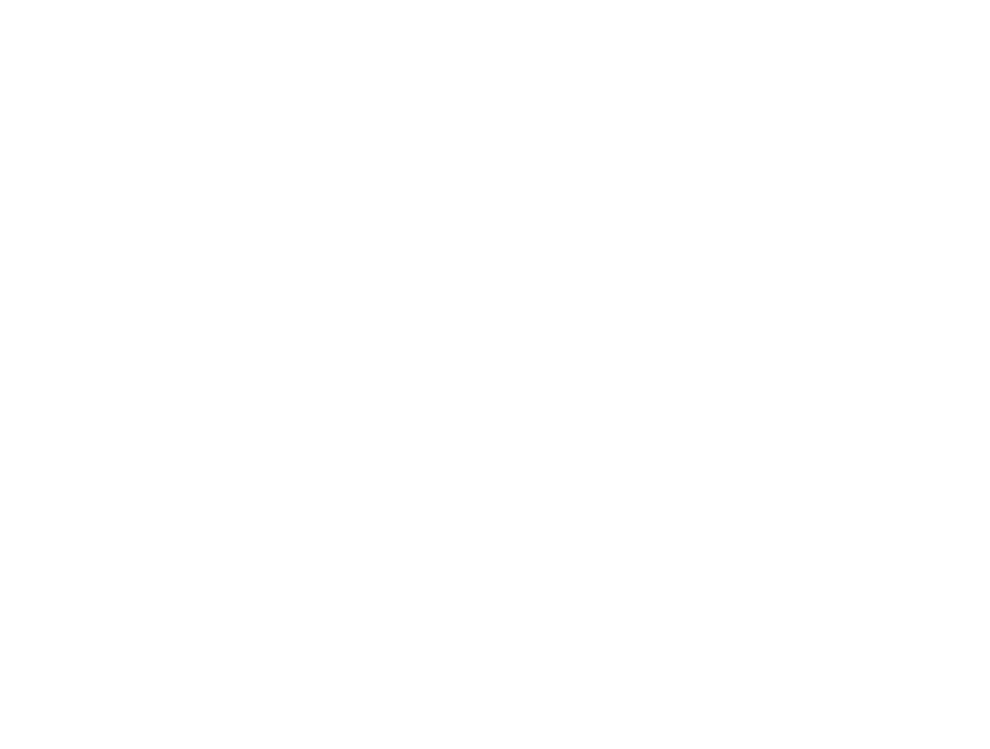

In [4]:
snack_summary = survey_df["snack_choice"].value_counts()
print(snack_summary)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    snack_summary.index,
    snack_summary.values,
    width=0.48,
    color=["#1F6E8C", "#3D5A80", "#D97757"],
    edgecolor="#1E293B",
    linewidth=0.8
)
ax.set_title("Student Snack Choices", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Snack")
ax.set_ylabel("Number of Students")
ax.set_ylim(0, 46)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.8,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Q4: Compare tea preference by age group.

In [5]:
age_tea_table = survey_df.groupby(["age_group", "tea_type"]).size().unstack(fill_value=0)
print("Tea preference by age group:")
print(age_tea_table)

Tea preference by age group:
tea_type   Black  Doodh Patti  Green
age_group                           
18-20          9           11     13
21-23          9            6      5
24-26          5            8     11


### Q5: Count the number of students who don't drink tea.

In [6]:
non_drinkers = (survey_df["prefers_tea"].str.strip().str.casefold() == "no").sum()
print(f"Number of students who do not drink tea: {non_drinkers}")

Number of students who do not drink tea: 49
